# 02 — Classical models (TF-IDF + stylometric features)

The five deployed sklearn models — LinearSVC, Logistic Regression, Multinomial
NB, Random Forest, Gradient Boosting — evaluated **from their saved
checkpoints, no retraining**, on the leak-free held-out set from
`aitextd.splits` (v1-test documents present in the v2 corpus,
doc_id-deduplicated: nothing these checkpoints were trained on).

Every number comes from the shared battery in `aitextd.metrics`
(`evaluation_report`): ranking quality, low-FPR operating points (RAID-style
TPR@1%/5%), agreement metrics (MCC, kappa), calibration (ECE/ACE/MCE/Brier/
NLL/slope), stratified bootstrap confidence intervals and paired significance
tests (DeLong, McNemar) against the strongest model.

In [2]:
import warnings

import joblib
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.special import expit
from sklearn.exceptions import InconsistentVersionWarning

from aitextd import metrics, paths, plots, registry, splits
from aitextd.features import STYLE_FEATURE_NAMES, compute_style_features, style_features_vector
from aitextd.text import tokenize_persian_text

# deployed joblib checkpoints were pickled under an older scikit-learn
warnings.filterwarnings("ignore", category=InconsistentVersionWarning)

SEED = 42
TREE_FEATURE_COUNT = 30_000
RUN_TRAINING = False  # True: rerun the complete training procedure below (~30 min on CPU)

In [3]:
# Evaluation set: joint feature layout the family was fit on —
# TF-IDF over shekar-tokenized text, then the style columns.
heldout = splits.deployed_heldout_frame()
tokenized = splits.v1_tokens()
held_texts = [" ".join(tokenized[row]) for row in heldout["v1_row"]]
y_held = heldout["label_binary"].to_numpy()

style_table = pd.read_parquet(paths.DATA_DIR / "style_features_v2.parquet")
style = heldout[["doc_id"]].merge(style_table, on="doc_id")[STYLE_FEATURE_NAMES].to_numpy()

vectorizer = joblib.load(paths.TFIDF_VECTORIZER_JOBLIB)
X_held = sparse.hstack([vectorizer.transform(held_texts), style], format="csr")
tfidf_dim = len(vectorizer.get_feature_names_out())
print(f"held-out set: {len(heldout)} documents | joint matrix {X_held.shape} (tfidf {tfidf_dim} + style {style.shape[1]})")

held-out set: 4056 documents | joint matrix (4056, 150010) (tfidf 150000 + style 10)


In [4]:
FILENAMES = {
    "svm": "svModel.joblib",
    "logreg": "logregModel.joblib",
    "naive_bayes": "nbModel.joblib",
    "random_forest": "rfModel.joblib",
    "gradient_boosting": "gbModel.joblib",
}
models = {mid: joblib.load(paths.model_path(fname)) for mid, fname in FILENAMES.items()}
print("models ready:", ", ".join(models))

models ready: svm, logreg, naive_bayes, random_forest, gradient_boosting


## Standard training procedure (complete, flag-guarded)

The **complete** pipeline that produced the deployed artifacts: v1 training
matrix -> the five model constructions with their recorded hyperparameters ->
fit on the full training split -> score on the v1 test split -> save to
`models/` -> refresh `models.json`.

**Not executed here** (`RUN_TRAINING = False`): the deployed checkpoints
provide the numbers below, and the evaluation cells run unchanged whether this
cell is skipped or rerun with `RUN_TRAINING = True`.

In [ ]:
if RUN_TRAINING:
    import time

    from sklearn.compose import ColumnTransformer
    from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
    from sklearn.feature_selection import SelectKBest, chi2
    from sklearn.linear_model import LogisticRegression
    from sklearn.naive_bayes import MultinomialNB
    from sklearn.pipeline import Pipeline
    from sklearn.svm import LinearSVC

    X_v1 = joblib.load(paths.TFIDF_X_JOBLIB)
    y_v1 = pd.read_csv(paths.PROCESSED_CSV, usecols=["aiGenerated"])["aiGenerated"].to_numpy()
    indices = joblib.load(paths.DATA_DIR / "split_indices.joblib")
    train_idx, test_idx = indices["train_idx"], indices["test_idx"]

    def demo_probs(clf, X):
        """AI probability: predict_proba when present, sigmoid margin otherwise."""
        if hasattr(clf, "predict_proba"):
            return clf.predict_proba(X)[:, 1]
        return expit(clf.decision_function(X))

    def tree_pipeline(clf):
        """chi2-select the TF-IDF columns; style columns pass through."""
        return Pipeline([
            ("select", ColumnTransformer([
                ("tfidf_select", SelectKBest(chi2, k=TREE_FEATURE_COUNT), slice(0, tfidf_dim)),
                ("style", "passthrough", slice(tfidf_dim, None)),
            ], sparse_threshold=1.0)),
            ("clf", clf),
        ])

    specs = {
        "svm": (LinearSVC(C=1.0, max_iter=5000, random_state=SEED), "svModel.joblib"),
        "logreg": (LogisticRegression(solver="liblinear", dual=True, C=32.0, max_iter=5000, random_state=SEED), "logregModel.joblib"),
        "naive_bayes": (MultinomialNB(alpha=0.01), "nbModel.joblib"),
        "random_forest": (tree_pipeline(RandomForestClassifier(
            n_estimators=300, n_jobs=-1, random_state=SEED, class_weight="balanced"
        )), "rfModel.joblib"),
        "gradient_boosting": (tree_pipeline(GradientBoostingClassifier(
            n_estimators=150, max_depth=3, learning_rate=0.1, random_state=SEED
        )), "gbModel.joblib"),
    }

    training_info = {
        "totalSamples": len(train_idx) + len(test_idx), "trainSamples": len(train_idx),
        "testSamples": len(test_idx), "featureCount": int(X_v1.shape[1]),
        "testSplitRatio": round(len(test_idx) / (len(train_idx) + len(test_idx)), 2),
        "randomSeed": SEED, "dataset": "persian_ai_generated_final.csv + blogs.csv",
    }

    fresh = {}
    for mid, (clf, filename) in specs.items():
        X_fit = X_v1[train_idx][:, :tfidf_dim] if mid in ("svm", "logreg") else X_v1[train_idx]
        X_score = X_v1[test_idx][:, :tfidf_dim] if mid in ("svm", "logreg") else X_v1[test_idx]
        print(f"training {mid} ...", flush=True)
        started = time.perf_counter()
        clf.fit(X_fit, y_v1[train_idx])
        report = metrics.evaluate(y_v1[test_idx], demo_probs(clf, X_score))
        joblib.dump(clf, paths.model_path(filename))
        registry.refresh_entry(mid, report, training_info)
        fresh[mid] = clf
        print(f"  {mid}: {time.perf_counter() - started:.0f}s | v1-test F1 {report['f1']:.4f}")

    models = fresh  # the evaluation cells below now score the fresh models
else:
    print("RUN_TRAINING=False — the deployed checkpoints are used below")

In [5]:
def model_probs(model, X):
    """AI probability, uniform across the family: predict_proba when present,
    numerically stable sigmoid of the margin for the linear models."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return expit(model.decision_function(X))


reports, probs_held = {}, {}
for mid, model in models.items():
    # svm / logreg were fit on the TF-IDF slice only
    X_eval = X_held[:, :tfidf_dim] if mid in ("svm", "logreg") else X_held
    probs_held[mid] = model_probs(model, X_eval)
    reports[mid] = metrics.evaluation_report(y_held, probs_held[mid])
print("evaluated:", ", ".join(reports))

evaluated: svm, logreg, naive_bayes, random_forest, gradient_boosting


In [6]:
metrics.evaluation_table(reports, metrics.RANKING_COLUMNS)

,roc_auc,pr_auc,pauc_5,tpr_at_fpr_1,tpr_at_fpr_5,fpr_at_tpr_90
model,,,,,,
svm,0.9999,0.9999,0.9989,0.9995,0.9995,0.0000
logreg,0.9999,0.9999,0.9984,0.9991,0.9995,0.0000
naive_bayes,0.9980,0.9981,0.9692,0.9715,0.9919,0.0046
random_forest,0.9993,0.9994,0.9912,0.9910,0.9967,0.0000
gradient_boosting,0.9995,0.9996,0.9942,0.9919,0.9986,0.0000


In [6]:
metrics.evaluation_table(reports, metrics.THRESHOLD_COLUMNS)

,accuracy,balanced_accuracy,macro_f1,mcc,kappa,precision,recall,f1,fpr
model,,,,,,,,,
svm,0.9970,0.9971,0.9970,0.9941,0.9941,0.9981,0.9962,0.9971,0.0021
logreg,0.9968,0.9968,0.9968,0.9936,0.9936,0.9981,0.9957,0.9969,0.0021
naive_bayes,0.9813,0.9816,0.9812,0.9626,0.9625,0.9903,0.9734,0.9818,0.0103
random_forest,0.9887,0.9889,0.9886,0.9774,0.9773,0.9947,0.9834,0.9890,0.0056
gradient_boosting,0.9896,0.9900,0.9896,0.9794,0.9793,0.9990,0.9810,0.9899,0.0010


In [7]:
metrics.evaluation_table(reports, metrics.CALIBRATION_COLUMNS)

,ece,ace,mce,brier,nll,calibration_slope,calibration_intercept
model,,,,,,,
svm,0.2295,0.2208,0.3829,0.0589,0.2694,9.3988,0.7900
logreg,0.0107,0.0081,0.5327,0.0036,0.0187,1.8930,0.5906
naive_bayes,0.0146,0.0124,0.7093,0.0156,0.0954,0.4389,0.5825
random_forest,0.1056,0.1023,0.3410,0.0260,0.1361,4.3251,0.7372
gradient_boosting,0.0236,0.0240,0.4347,0.0095,0.0442,2.0306,1.5016


<Axes: title={'left': 'Classical models — leak-free held-out set'}>

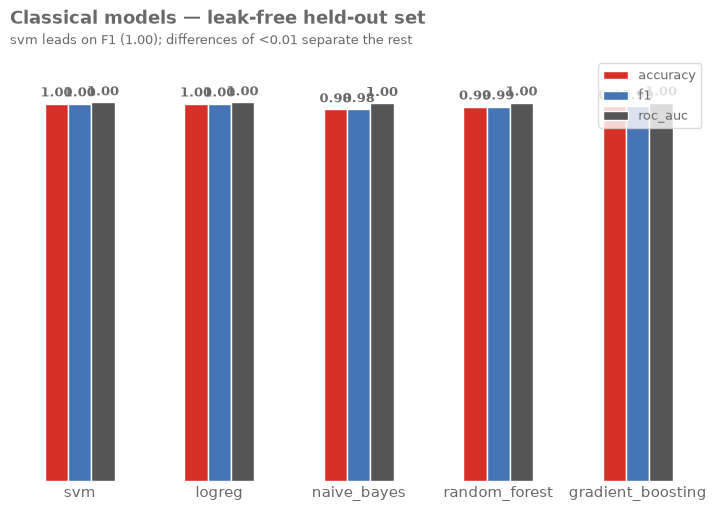

In [8]:
plots.metric_bars(reports, "Classical models — leak-free held-out set")

<Axes: title={'center': 'svm'}, xlabel='prediction'>

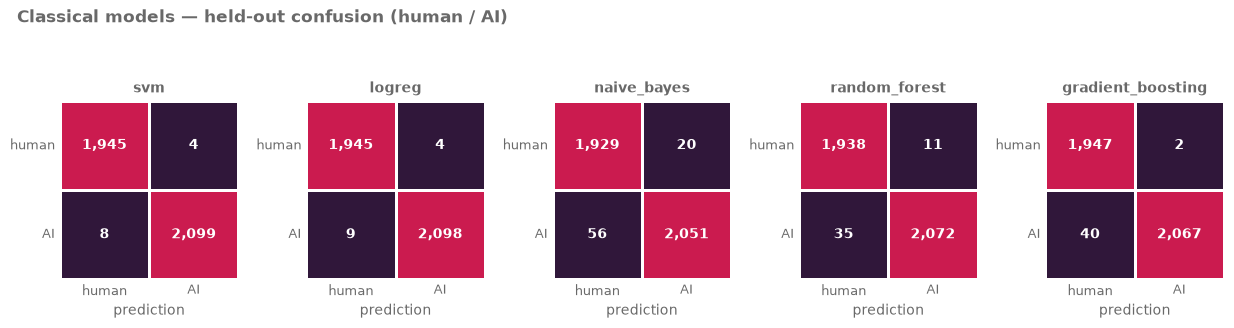

In [9]:
plots.confusion_grid(reports, "Classical models — held-out confusion (human / AI)")

<Axes: title={'left': 'Classical models — ROC, low-FPR region'}, xlabel='False Positive Rate (log scale)', ylabel='True Positive Rate'>

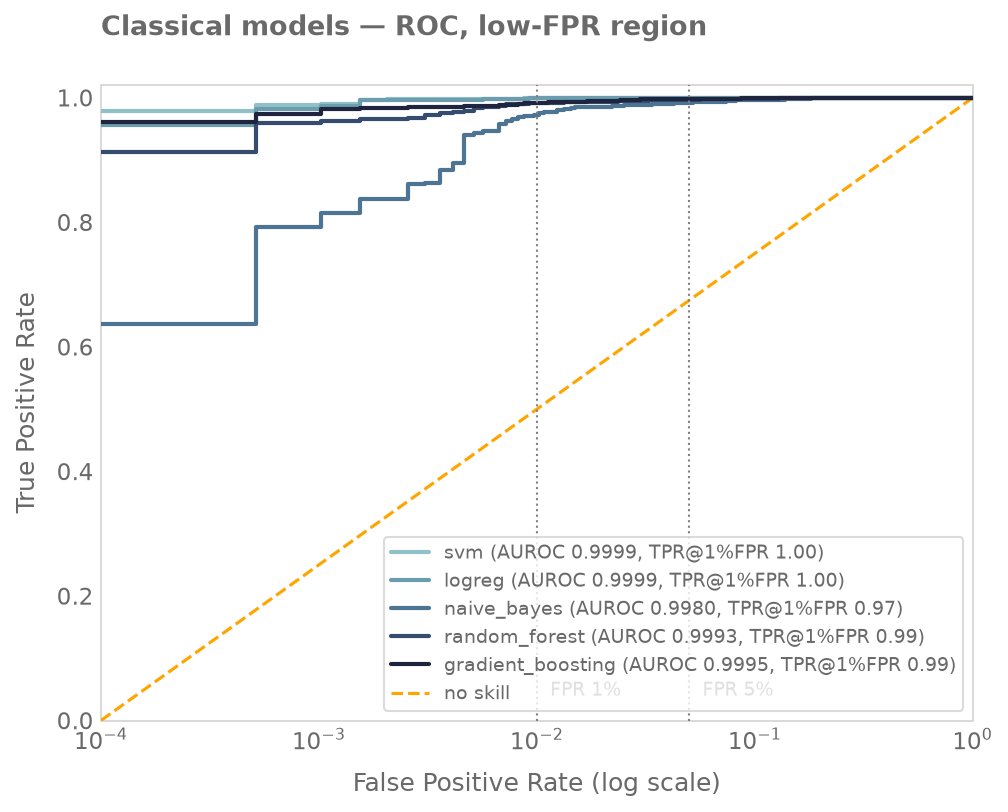

In [10]:
plots.roc_curves_log(y_held, probs_held, "Classical models — ROC, low-FPR region")

<Axes: title={'left': 'svm\nECE 0.230'}, ylabel='empirical accuracy'>

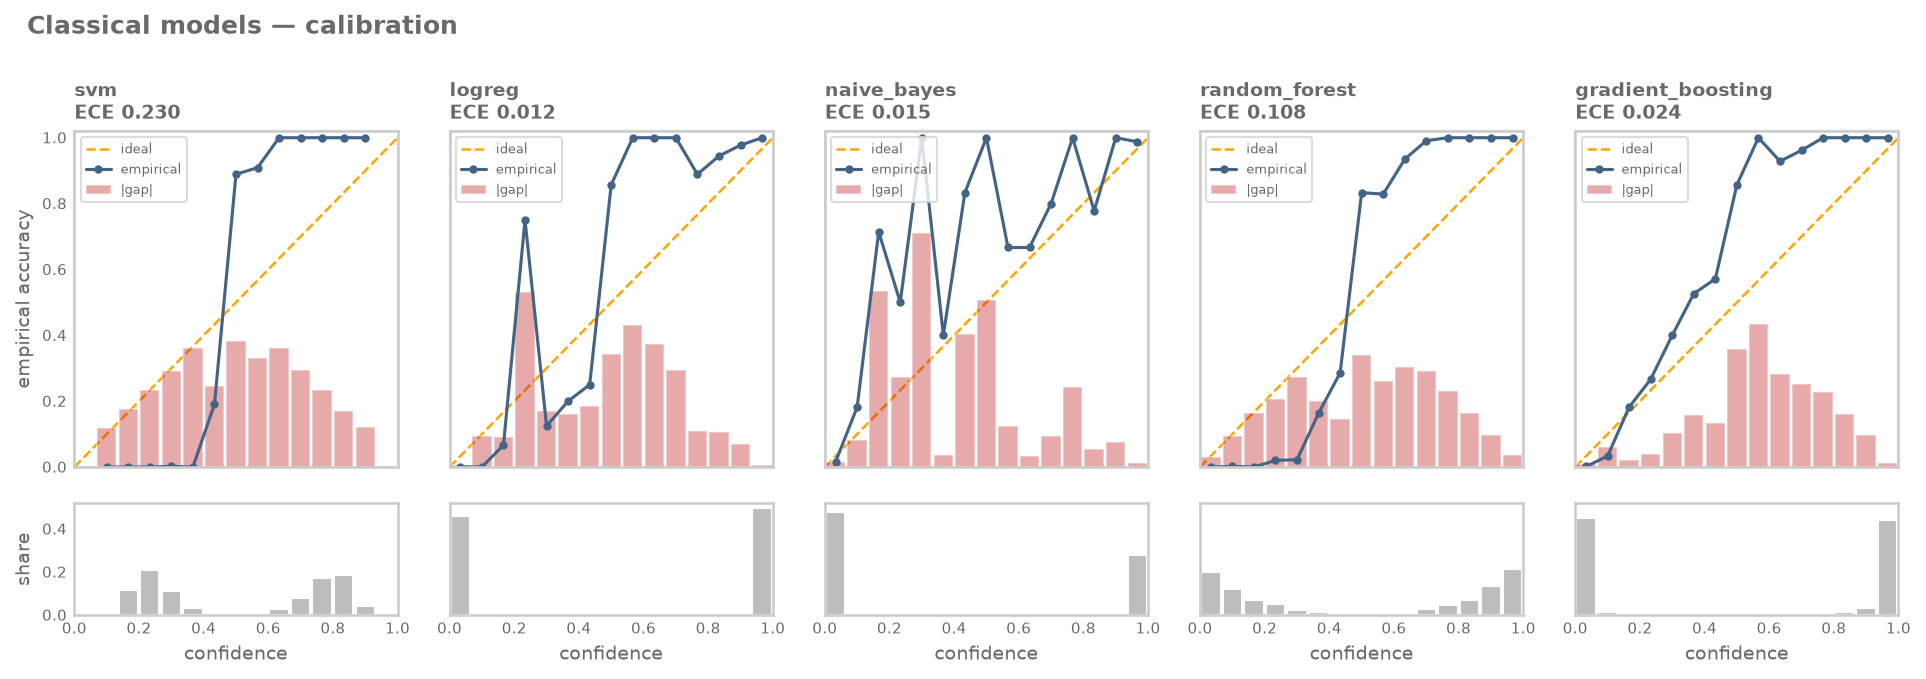

In [11]:
plots.reliability_grid(y_held, probs_held, title="Classical models — calibration")

<Axes: title={'left': 'svm'}, xlabel='AI probability', ylabel='density'>

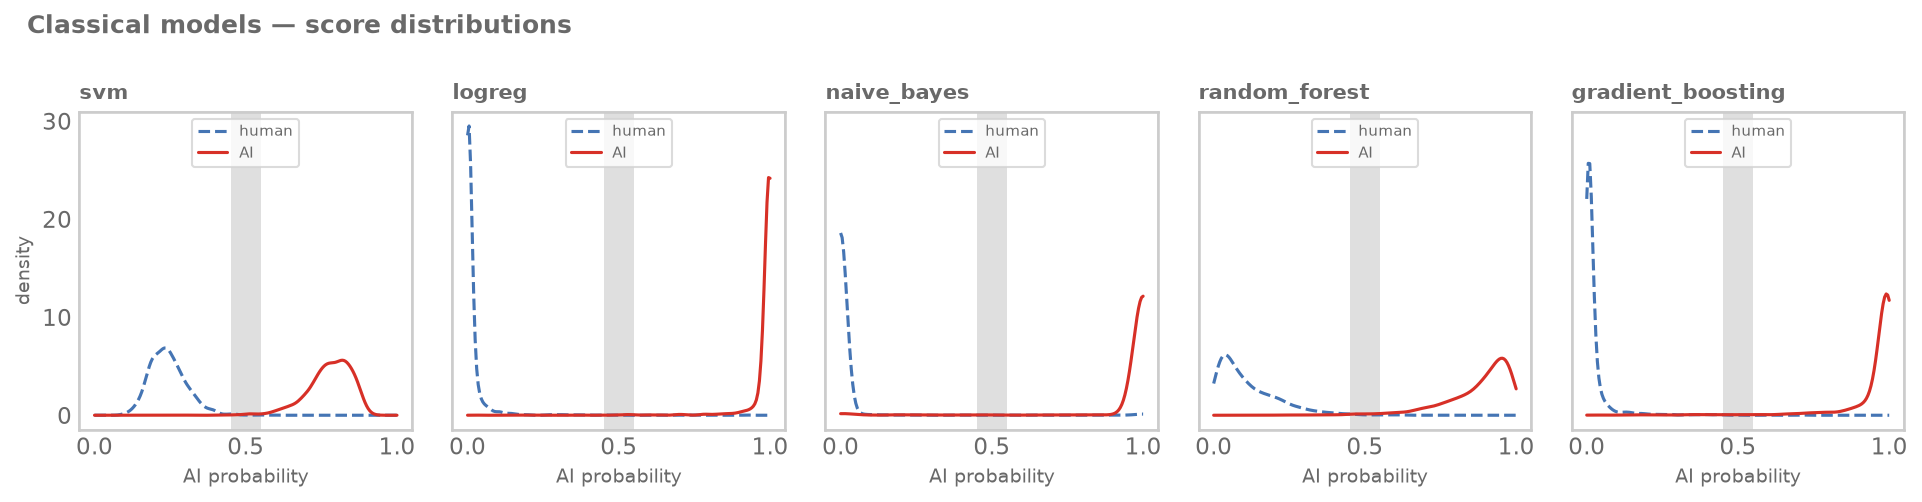

In [12]:
plots.score_distributions(y_held, probs_held, "Classical models — score distributions")

In [13]:
# Stratified bootstrap 95% CI on the three headline metrics
ci_rows = {
    mid: metrics.bootstrap_ci(y_held, probs, ("roc_auc", "f1", "tpr_at_fpr_1"), n_boot=1000, seed=SEED)
    for mid, probs in probs_held.items()
}
pd.DataFrame({
    metric: {mid: f"[{lo:.3f}, {hi:.3f}]" for mid, per_metric in ci_rows.items() for lo, hi in [per_metric[metric]]}
    for metric in ("roc_auc", "f1", "tpr_at_fpr_1")
}).rename_axis("model")

,roc_auc,f1,tpr_at_fpr_1
model,,,
svm,"[1.000, 1.000]","[0.996, 0.999]","[0.998, 1.000]"
logreg,"[1.000, 1.000]","[0.995, 0.998]","[0.996, 1.000]"
naive_bayes,"[0.997, 0.999]","[0.978, 0.986]","[0.946, 0.985]"
random_forest,"[0.999, 1.000]","[0.986, 0.992]","[0.983, 0.995]"
gradient_boosting,"[0.999, 1.000]","[0.987, 0.993]","[0.985, 0.996]"


In [14]:
# Paired significance tests against the strongest model (highest F1)
best = max(reports, key=lambda mid: reports[mid]["f1"])
delong = pd.DataFrame({
    mid: metrics.delong_test(y_held, probs_held[best], probs)
    for mid, probs in probs_held.items() if mid != best
}).T
print(f"DeLong test vs {best}:")
delong

DeLong test vs svm:


,auc_a,auc_b,z,p_value
logreg,0.9999,0.9999,1.4408,0.1497
naive_bayes,0.9999,0.9980,5.0546,0.0000
random_forest,0.9999,0.9993,3.6264,0.0003
gradient_boosting,0.9999,0.9995,2.1306,0.0331


In [15]:
mcnemar = pd.DataFrame({
    mid: metrics.mcnemar_test(y_held, probs_held[best], probs)
    for mid, probs in probs_held.items() if mid != best
}).T
print(f"McNemar test vs {best}:")
mcnemar

McNemar test vs svm:


,n01,n10,p_value
logreg,1.0,2.0,1.0
naive_bayes,4.0,68.0,0.0
random_forest,5.0,39.0,0.0
gradient_boosting,8.0,38.0,0.0


tokenized 120/1200
tokenized 240/1200
tokenized 360/1200
tokenized 480/1200
tokenized 600/1200
tokenized 720/1200
tokenized 840/1200
tokenized 960/1200
tokenized 1080/1200
tokenized 1200/1200
style features 120/1200
style features 240/1200
style features 360/1200
style features 480/1200
style features 600/1200
style features 720/1200
style features 840/1200
style features 960/1200
style features 1080/1200
style features 1200/1200


<Axes: title={'left': 'Attack success rate under paraphrasing'}, xlabel='attack success rate'>

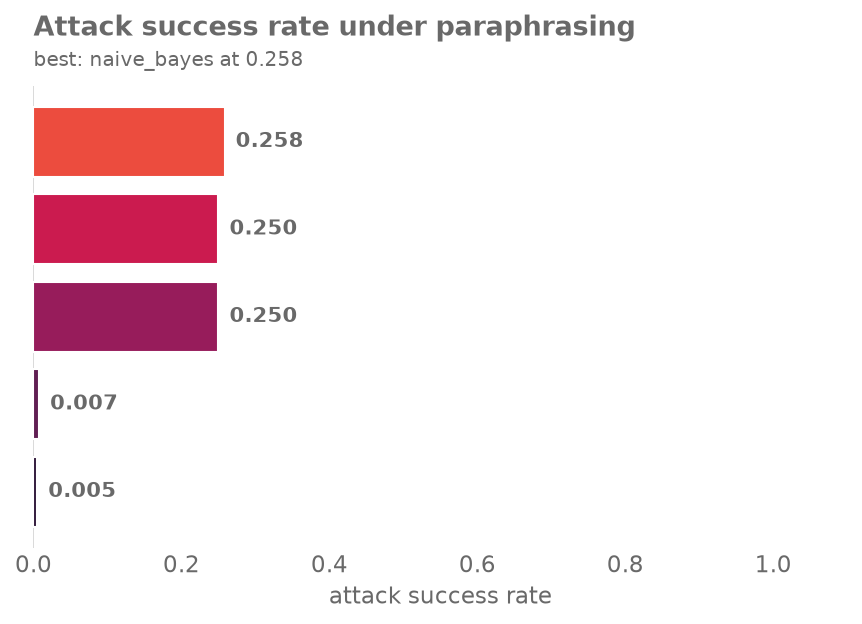

In [7]:
import warnings

from joblib import Parallel, delayed

attack = pd.read_parquet(paths.DATA_DIR / "paraphrase_attack.parquet")
texts_attack = attack["text"].astype(str).tolist()
chunk = max(1, len(texts_attack) // 10)

attack_tokens = []
for start in range(0, len(texts_attack), chunk):
    attack_tokens.extend(
        Parallel(n_jobs=-1)(
            delayed(tokenize_persian_text)(t) for t in texts_attack[start : start + chunk]
        )
    )
    print(f"tokenized {min(start + chunk, len(texts_attack))}/{len(texts_attack)}")

attack_style_rows = []
for start in range(0, len(texts_attack), chunk):
    attack_style_rows.extend(
        style_features_vector(compute_style_features(t, " ".join(tok), vectorizer))[0]
        for t, tok in zip(
            texts_attack[start : start + chunk], attack_tokens[start : start + chunk], strict=True
        )
    )
    print(f"style features {min(start + chunk, len(texts_attack))}/{len(texts_attack)}")

X_attack = sparse.hstack(
    [vectorizer.transform([" ".join(t) for t in attack_tokens]), np.asarray(attack_style_rows)],
    format="csr",
)

# Attack Success Rate: share of AI texts that evade detection after paraphrasing
asr = {}
with warnings.catch_warnings():
    # attack rows are all AI, so ROC-based metrics are undefined and unused here
    warnings.simplefilter("ignore")
    for mid, model in models.items():
        X_eval = X_attack[:, :tfidf_dim] if mid in ("svm", "logreg") else X_attack
        asr[mid] = round(1.0 - metrics.evaluate(attack["label_binary"].to_numpy(), model_probs(model, X_eval))["recall"], 4)
plots.bar_series(
    pd.Series(asr, name="ASR"), "Attack success rate under paraphrasing", "attack success rate"
)

## Summary

- Tables: ranking quality, threshold metrics, calibration — one row per model,
  all from `aitextd.metrics.evaluation_report`.
- Charts: bars, confusions, log-scale ROC, reliability, score distributions.
- `ci_rows` — stratified bootstrap 95% CIs; DeLong/McNemar — paired tests vs
  the strongest model; `asr` — paraphrase attack success rate.